# Customer Churn: Data Quality & Exploratory Analysis
**Track:** Data Analytics · Task 02 · Dataset: synthetic subscription customers (EdVyro)

**Decision question (from the EdVyro churn guide):** Which customer groups should a fictional subscription team contact first to reduce avoidable churn?

**Notebook flow:** 1) Load & profile → 2) Quality audit → 3) Clean + validate → 4) Summary stats → 5) Distributions → 6) Findings & limits.

> ⚠️ The dataset has only **15 rows**. Everything below is *descriptive*. No predictions and no causal claims.

In [1]:
import pandas as pd, numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

RAW = "data/customer_churn_raw.csv"
raw = pd.read_csv(RAW)
print("Shape:", raw.shape)
display(raw)

Shape: (15, 11)


,CustomerID,Gender,Age,TenureMonths,SubscriptionType,MonthlyCharges,TotalCharges,ContractType,SupportTickets,PaymentMethod,Churn
0,CUST-1001,Female,34,12,Basic,49.99,599.88,Month-to-Month,3,Credit Card,Yes
1,CUST-1002,Male,45,24,Pro,79.99,1919.76,One Year,1,Bank Transfer,No
2,CUST-1003,Female,29,6,Basic,49.99,299.94,Month-to-Month,5,UPI,Yes
3,CUST-1004,Male,52,36,Enterprise,149.99,5399.64,Two Year,0,Credit Card,No
4,CUST-1005,Female,41,8,Pro,79.99,639.92,Month-to-Month,4,Debit Card,Yes
5,CUST-1006,Male,31,18,Basic,49.99,899.82,One Year,2,UPI,No
6,CUST-1007,Female,23,3,Basic,49.99,149.97,Month-to-Month,6,Credit Card,Yes
7,CUST-1008,Male,60,48,Enterprise,149.99,7199.52,Two Year,1,Bank Transfer,No
8,CUST-1009,Female,38,15,Pro,79.99,1199.85,One Year,2,Credit Card,No
9,CUST-1010,Male,27,4,Basic,49.99,199.96,Month-to-Month,4,UPI,Yes


## 1. Profile: columns, types, missing values

In [2]:
profile = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non_null": raw.notna().sum(),
    "missing": raw.isna().sum(),
    "missing_%": (raw.isna().mean()*100).round(1),
    "n_unique": raw.nunique(),
})
display(profile)

,dtype,non_null,missing,missing_%,n_unique
CustomerID,str,15,0,0.0,15
Gender,str,15,0,0.0,2
Age,int64,15,0,0.0,15
TenureMonths,int64,15,0,0.0,15
SubscriptionType,str,15,0,0.0,3
MonthlyCharges,float64,15,0,0.0,3
TotalCharges,float64,15,0,0.0,15
ContractType,str,15,0,0.0,3
SupportTickets,int64,15,0,0.0,7
PaymentMethod,str,15,0,0.0,4


## 2. Quality audit (nothing is changed yet)
Checks: duplicates, whitespace/casing inconsistencies, category labels, impossible values, outliers, and internal consistency of `TotalCharges`.

In [3]:
audit = {}
audit["duplicate full rows"] = int(raw.duplicated().sum())
audit["duplicate CustomerID"] = int(raw["CustomerID"].duplicated().sum())
audit["CustomerID format != CUST-####"] = int((~raw["CustomerID"].str.match(r"^CUST-\d{4}$")).sum())

text_cols = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
audit["text cells with leading/trailing spaces"] = int(sum((raw[c] != raw[c].str.strip()).sum() for c in text_cols))

audit["Age outside 18-100"] = int((~raw["Age"].between(18,100)).sum())
audit["TenureMonths < 0"] = int((raw["TenureMonths"]<0).sum())
audit["MonthlyCharges <= 0"] = int((raw["MonthlyCharges"]<=0).sum())
audit["SupportTickets < 0"] = int((raw["SupportTickets"]<0).sum())

gap = (raw["MonthlyCharges"]*raw["TenureMonths"] - raw["TotalCharges"]).round(2)
audit["TotalCharges != Monthly x Tenure (>0.01)"] = int((gap.abs()>0.01).sum())

display(pd.Series(audit, name="rows affected").to_frame())

print("\nCategory labels:")
for c in ["Gender","SubscriptionType","ContractType","PaymentMethod","Churn"]:
    print(f"  {c}: {sorted(raw[c].unique())}")

# Outliers: IQR rule (1.5 x IQR), reported but NOT removed
num = ["Age","TenureMonths","MonthlyCharges","TotalCharges","SupportTickets"]
rows=[]
for c in num:
    q1,q3 = raw[c].quantile([.25,.75]); iqr=q3-q1
    lo,hi = q1-1.5*iqr, q3+1.5*iqr
    flagged = raw.loc[(raw[c]<lo)|(raw[c]>hi),"CustomerID"].tolist()
    rows.append([c, round(lo,2), round(hi,2), len(flagged), ", ".join(flagged) or "-"])
outl = pd.DataFrame(rows, columns=["column","lower_fence","upper_fence","n_flagged","customers"])
display(outl)

,rows affected
duplicate full rows,0
duplicate CustomerID,0
CustomerID format != CUST-####,0
text cells with leading/trailing spaces,0
Age outside 18-100,0
TenureMonths < 0,0
MonthlyCharges <= 0,0
SupportTickets < 0,0
TotalCharges != Monthly x Tenure (>0.01),0



Category labels:
  Gender: ['Female', 'Male']
  SubscriptionType: ['Basic', 'Enterprise', 'Pro']
  ContractType: ['Month-to-Month', 'One Year', 'Two Year']
  PaymentMethod: ['Bank Transfer', 'Credit Card', 'Debit Card', 'UPI']
  Churn: ['No', 'Yes']


,column,lower_fence,upper_fence,n_flagged,customers
0,Age,4.50,72.50,0,-
1,TenureMonths,-23.00,57.00,0,-
2,MonthlyCharges,-47.51,212.49,0,-
3,TotalCharges,-3689.82,7349.46,0,-
4,SupportTickets,-3.50,8.50,0,-


**How to read this:** with n = 15 the IQR fence is a coarse screen. Any flagged value must be judged against business logic (e.g. a 48-month Enterprise customer paying the Enterprise price is *plausible*, not an error). Flagged values are **kept** and noted in the cleaning log.

**Schema note:** the EdVyro guide describes `monthly_charge`, `contract_type: monthly/quarterly/annual` and `churned`. The file actually uses `MonthlyCharges`, `Month-to-Month / One Year / Two Year`, and `Churn` (Yes/No). I mapped these explicitly (see data dictionary) rather than assuming they match.

## 3. Clean, with a logged reason for every change

In [4]:
log = []   # (step, action, rows_affected, reason)
df = raw.copy()

# 3.1 snake_case column names
rename = {"CustomerID":"customer_id","Gender":"gender","Age":"age","TenureMonths":"tenure_months",
          "SubscriptionType":"subscription_type","MonthlyCharges":"monthly_charges",
          "TotalCharges":"total_charges","ContractType":"contract_type",
          "SupportTickets":"support_tickets","PaymentMethod":"payment_method","Churn":"churn"}
df = df.rename(columns=rename)
log.append(("rename","Columns converted to snake_case",len(rename),"Consistent, code-friendly names"))

# 3.2 trim whitespace on text columns (defensive, audit found 0)
txt = ["customer_id","gender","subscription_type","contract_type","payment_method","churn"]
before = df[txt].copy()
for c in txt: df[c] = df[c].astype(str).str.strip()
log.append(("trim","Stripped whitespace in text columns",int((before!=df[txt]).any(axis=1).sum()),"Audit found none; kept as a safeguard"))

# 3.3 churn Yes/No -> 0/1 flag (original label kept)
df["churn_flag"] = df["churn"].map({"Yes":1,"No":0}).astype("int8")
assert df["churn_flag"].notna().all()
log.append(("encode","Added churn_flag (Yes=1, No=0)",len(df),"Needed to compute churn rates; original column retained"))

# 3.4 derived fields
df["expected_total_charges"] = (df["monthly_charges"]*df["tenure_months"]).round(2)
df["charge_gap"] = (df["total_charges"]-df["expected_total_charges"]).round(2)
df["tenure_band"] = pd.cut(df["tenure_months"],[0,6,12,24,60],labels=["0-6","7-12","13-24","25+"],right=True)
log.append(("derive","Added expected_total_charges, charge_gap, tenure_band",len(df),"Supports validation and grouped analysis"))

# 3.5 things deliberately NOT done
log.append(("duplicates","No rows removed",0,"0 duplicate rows / 0 duplicate IDs"))
log.append(("missing","No imputation",0,"0 missing values in any column"))
log.append(("outliers","No values capped/removed",0,"IQR flags reviewed; all values are business-plausible (see audit)"))

cleaning_log = pd.DataFrame(log, columns=["step","action","rows_affected","reason"])
display(cleaning_log)

,step,action,rows_affected,reason
0,rename,Columns converted to snake_case,11,"Consistent, code-friendly names"
1,trim,Stripped whitespace in text columns,0,Audit found none; kept as a safeguard
2,encode,"Added churn_flag (Yes=1, No=0)",15,Needed to compute churn rates; original column...
3,derive,"Added expected_total_charges, charge_gap, tenu...",15,Supports validation and grouped analysis
4,duplicates,No rows removed,0,0 duplicate rows / 0 duplicate IDs
5,missing,No imputation,0,0 missing values in any column
6,outliers,No values capped/removed,0,IQR flags reviewed; all values are business-pl...


### Validation checks (the notebook fails loudly if any of these break)

In [5]:
checks = {
 "row count unchanged (15)": len(df)==len(raw),
 "customer_id unique": df["customer_id"].is_unique,
 "no missing values in raw columns": df[list(rename.values())].notna().all().all(),
 "age within 18-100": df["age"].between(18,100).all(),
 "tenure_months >= 0": (df["tenure_months"]>=0).all(),
 "monthly_charges > 0": (df["monthly_charges"]>0).all(),
 "support_tickets >= 0": (df["support_tickets"]>=0).all(),
 "churn only Yes/No": set(df["churn"])=={"Yes","No"},
 "total_charges = monthly x tenure (+/-0.01)": (df["charge_gap"].abs()<=0.01).all(),
 "each subscription_type has one price": (df.groupby("subscription_type")["monthly_charges"].nunique()==1).all(),
}
res = pd.Series(checks, name="passed").to_frame()
display(res)
assert res["passed"].all(), "A validation check failed"
print("All", len(res), "validation checks passed")

df.to_csv("data/customer_churn_clean.csv", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False)
print("Saved clean dataset:", df.shape)

,passed
row count unchanged (15),True
customer_id unique,True
no missing values in raw columns,True
age within 18-100,True
tenure_months >= 0,True
monthly_charges > 0,True
support_tickets >= 0,True
churn only Yes/No,True
total_charges = monthly x tenure (+/-0.01),True
each subscription_type has one price,True


All 10 validation checks passed
Saved clean dataset: (15, 15)


## 4. Summary statistics

In [6]:
num_cols = ["age","tenure_months","monthly_charges","total_charges","support_tickets"]
display(df[num_cols].describe().round(2).T)

print("Overall churn rate:", f"{df['churn_flag'].mean():.1%}", f"({df['churn_flag'].sum()} of {len(df)})")

,count,mean,std,min,25%,50%,75%,max
age,15.0,39.07,11.39,23.00,30.00,38.00,47.00,60.00
tenure_months,15.0,18.80,14.33,2.00,7.00,15.00,27.00,48.00
monthly_charges,15.0,84.66,42.74,49.99,49.99,79.99,114.99,149.99
total_charges,15.0,2088.48,2407.37,99.98,449.91,1099.78,3209.73,7199.52
support_tickets,15.0,2.53,1.92,0.00,1.00,2.00,4.00,6.00


Overall churn rate: 46.7% (7 of 15)


In [7]:
def churn_by(col):
    g = df.groupby(col, observed=True).agg(customers=("customer_id","count"),
            churned=("churn_flag","sum"), churn_rate=("churn_flag","mean"),
            avg_tenure=("tenure_months","mean"), avg_tickets=("support_tickets","mean"),
            monthly_revenue=("monthly_charges","sum")).round(2)
    g["churn_rate"] = (g["churn_rate"]*100).round(1).astype(str)+"%"
    return g
for c in ["contract_type","subscription_type","payment_method","gender","tenure_band"]:
    print(f"\n--- churn by {c} ---"); display(churn_by(c))


--- churn by contract_type ---


,customers,churned,churn_rate,avg_tenure,avg_tickets,monthly_revenue
contract_type,,,,,,
Month-to-Month,7,7,100.0%,7.00,4.29,409.93
One Year,4,0,0.0%,19.75,1.50,259.96
Two Year,4,0,0.0%,38.50,0.50,599.96



--- churn by subscription_type ---


,customers,churned,churn_rate,avg_tenure,avg_tickets,monthly_revenue
subscription_type,,,,,,
Basic,7,5,71.0%,9.57,3.71,349.93
Enterprise,4,0,0.0%,38.50,0.50,599.96
Pro,4,2,50.0%,15.25,2.50,319.96



--- churn by payment_method ---


,customers,churned,churn_rate,avg_tenure,avg_tickets,monthly_revenue
payment_method,,,,,,
Bank Transfer,3,0,0.0%,31.33,1.0,279.97
Credit Card,6,2,33.0%,22.67,2.0,629.94
Debit Card,2,2,100.0%,11.00,3.5,159.98
UPI,4,3,75.0%,7.50,4.0,199.96



--- churn by gender ---


,customers,churned,churn_rate,avg_tenure,avg_tickets,monthly_revenue
gender,,,,,,
Female,8,4,50.0%,17.00,2.75,659.92
Male,7,3,43.0%,20.86,2.29,609.93



--- churn by tenure_band ---


,customers,churned,churn_rate,avg_tenure,avg_tickets,monthly_revenue
tenure_band,,,,,,
0-6,4,4,100.0%,3.75,5.0,199.96
7-12,2,2,100.0%,10.00,3.5,129.98
13-24,5,1,20.0%,18.60,1.8,339.95
25+,4,0,0.0%,38.50,0.5,599.96


In [8]:
print("Mean by churn status:")
display(df.groupby("churn")[["age","tenure_months","monthly_charges","support_tickets"]].agg(["mean","min","max"]).round(1))

print("Correlation with churn_flag (descriptive only; n=15, not causal):")
display(df[["age","tenure_months","monthly_charges","support_tickets","churn_flag"]].corr()["churn_flag"].drop("churn_flag").round(2).to_frame("corr"))

print("Cross-tab contract_type x churn:")
display(pd.crosstab(df["contract_type"], df["churn"]))
print("Cross-tab subscription_type x contract_type (is plan confounded with contract?):")
display(pd.crosstab(df["subscription_type"], df["contract_type"]))

Mean by churn status:


age         tenure_months         monthly_charges               \
       mean min max          mean min max            mean   min    max   
churn                                                                    
No     46.6  31  60          29.1  15  48           107.5  50.0  150.0   
Yes    30.4  23  41           7.0   2  14            58.6  50.0   80.0   

      support_tickets          
                 mean min max  
churn                          
No                1.0   0   2  
Yes               4.3   3   6

Correlation with churn_flag (descriptive only; n=15, not causal):


,corr
age,-0.73
tenure_months,-0.80
monthly_charges,-0.59
support_tickets,0.88


Cross-tab contract_type x churn:


churn,No,Yes
contract_type,,
Month-to-Month,0,7
One Year,4,0
Two Year,4,0


Cross-tab subscription_type x contract_type (is plan confounded with contract?):


contract_type,Month-to-Month,One Year,Two Year
subscription_type,,,
Basic,5,2,0
Enterprise,0,0,4
Pro,2,2,0


## 5. Distributions

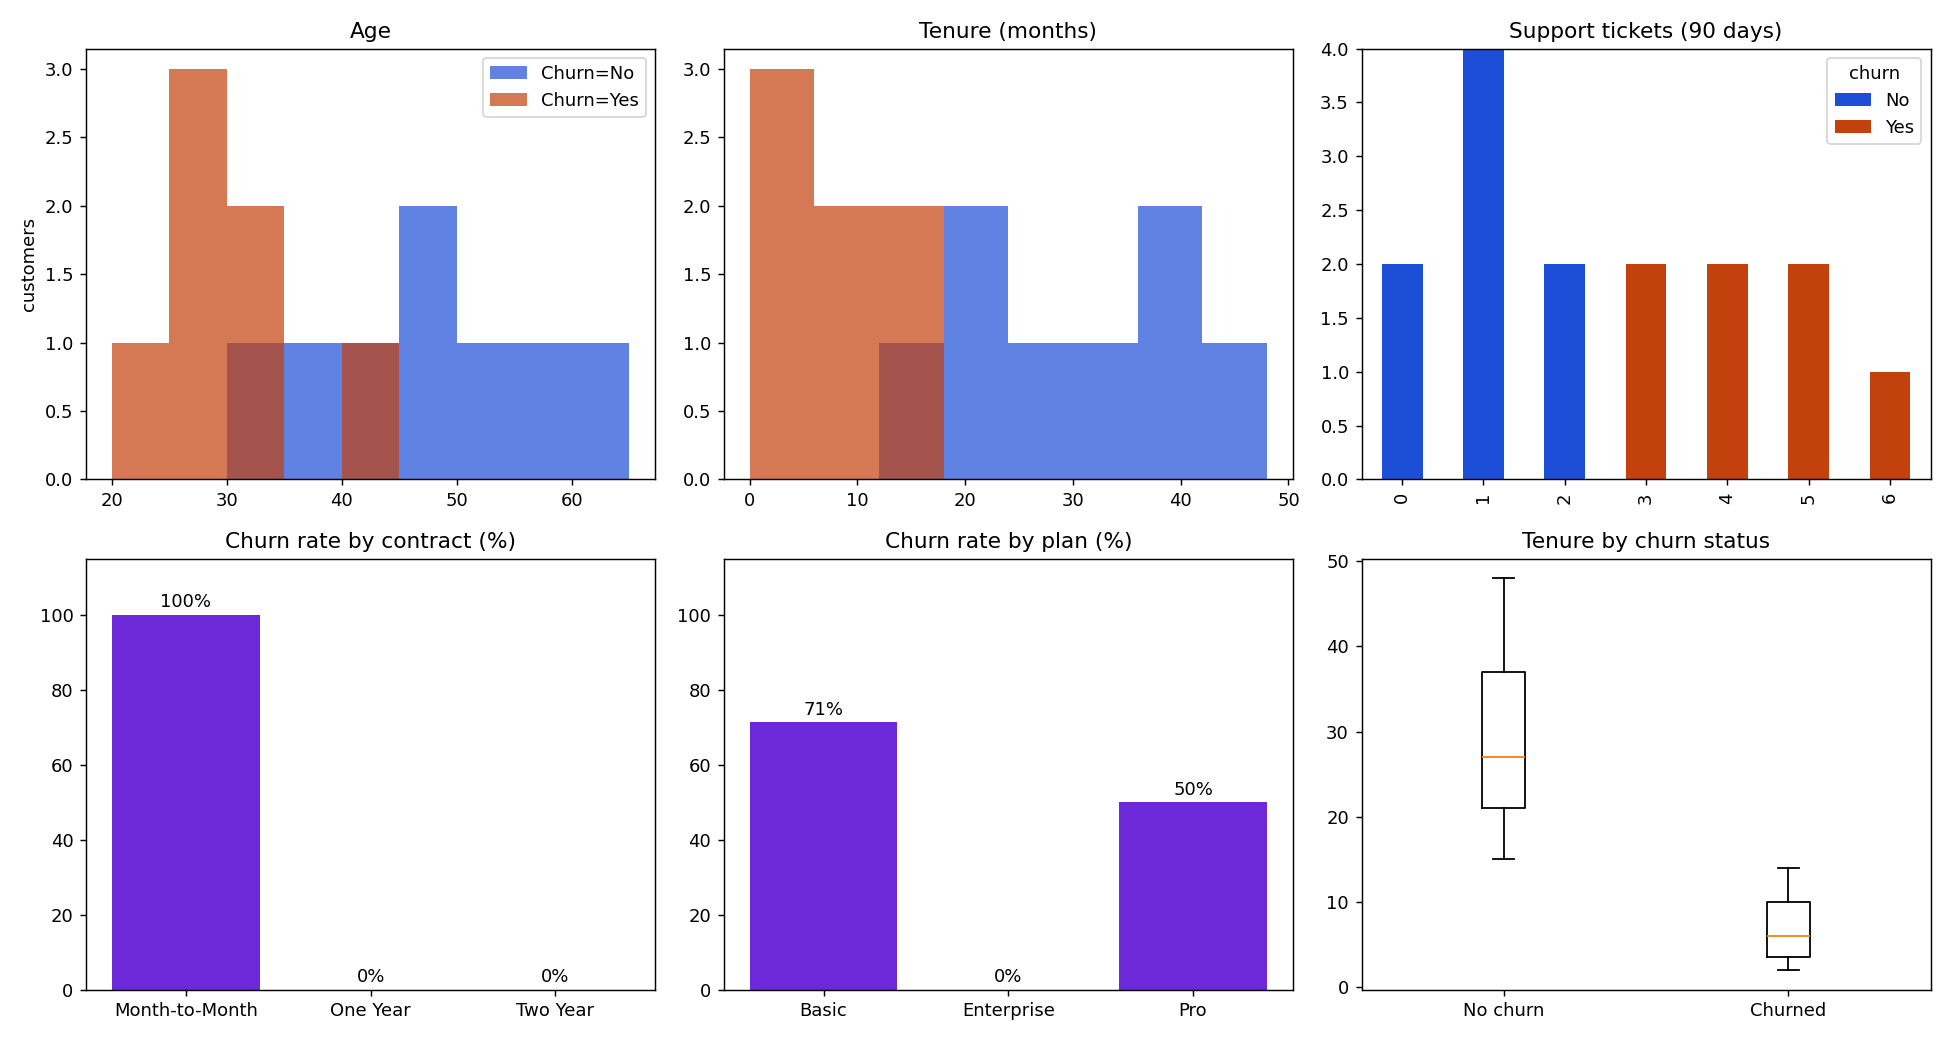

In [9]:
fig, ax = plt.subplots(2,3, figsize=(15,8))
cols = {"Yes":"#c2410c","No":"#1d4ed8"}

for lab,sub in df.groupby("churn"):
    ax[0,0].hist(sub["age"], bins=range(20,66,5), alpha=.7, label=f"Churn={lab}", color=cols[lab])
    ax[0,1].hist(sub["tenure_months"], bins=range(0,53,6), alpha=.7, label=f"Churn={lab}", color=cols[lab])
ax[0,0].set_title("Age"); ax[0,1].set_title("Tenure (months)")
ax[0,0].legend(); ax[0,0].set_ylabel("customers")

tick = df.groupby(["support_tickets","churn"]).size().unstack(fill_value=0)
tick.plot(kind="bar", stacked=True, ax=ax[0,2], color=[cols["No"],cols["Yes"]])
ax[0,2].set_title("Support tickets (90 days)"); ax[0,2].set_xlabel("")

rate = df.groupby("contract_type")["churn_flag"].mean().mul(100)
ax[1,0].bar(rate.index, rate.values, color="#6d28d9")
for i,v in enumerate(rate.values): ax[1,0].text(i, v+2, f"{v:.0f}%", ha="center")
ax[1,0].set_ylim(0,115); ax[1,0].set_title("Churn rate by contract (%)")

rate = df.groupby("subscription_type")["churn_flag"].mean().mul(100)
ax[1,1].bar(rate.index, rate.values, color="#6d28d9")
for i,v in enumerate(rate.values): ax[1,1].text(i, v+2, f"{v:.0f}%", ha="center")
ax[1,1].set_ylim(0,115); ax[1,1].set_title("Churn rate by plan (%)")

data = [df.loc[df.churn=="No","tenure_months"], df.loc[df.churn=="Yes","tenure_months"]]
ax[1,2].boxplot(data, tick_labels=["No churn","Churned"]); ax[1,2].set_title("Tenure by churn status")
plt.tight_layout(); plt.savefig("figures/eda_overview.png", dpi=130); plt.close()
display(Image("figures/eda_overview.png"))

## 6. Findings, limits, recommendation

In [10]:
mtm = df[df.contract_type=="Month-to-Month"]
rest = df[df.contract_type!="Month-to-Month"]
print(f"Month-to-Month: {len(mtm)} customers, churn {mtm.churn_flag.mean():.0%}, tenure range {mtm.tenure_months.min()}-{mtm.tenure_months.max()}, tickets range {mtm.support_tickets.min()}-{mtm.support_tickets.max()}")
print(f"1/2-year      : {len(rest)} customers, churn {rest.churn_flag.mean():.0%}, tenure range {rest.tenure_months.min()}-{rest.tenure_months.max()}, tickets range {rest.support_tickets.min()}-{rest.support_tickets.max()}")
print()
print("Churned customers with 3+ tickets:", int(((df.churn_flag==1)&(df.support_tickets>=3)).sum()), "of", int(df.churn_flag.sum()))
print("Retained customers with 3+ tickets:", int(((df.churn_flag==0)&(df.support_tickets>=3)).sum()))
print("Monthly revenue of churned customers: INR", round(df.loc[df.churn_flag==1,'monthly_charges'].sum(),2),
      "of", round(df.monthly_charges.sum(),2), "total")

Month-to-Month: 7 customers, churn 100%, tenure range 2-14, tickets range 3-6
1/2-year      : 8 customers, churn 0%, tenure range 15-48, tickets range 0-2

Churned customers with 3+ tickets: 7 of 7
Retained customers with 3+ tickets: 0
Monthly revenue of churned customers: INR 409.93 of 1269.85 total


**Findings (descriptive)**
1. **Churn is 7 of 15 (46.7%)**, and *every* churner is on a Month-to-Month contract; no One-Year or Two-Year customer left.
2. Churners are **short-tenure** (2-14 months) with **high ticket counts** (3-6 in 90 days). Retained customers have 0-2 tickets and 15-48 months of tenure, so the two groups don't overlap on either measure.
3. Plan and payment method also show churn differences (Basic 71%, Enterprise 0%; UPI 75%, Bank Transfer 0%), but they overlap heavily with contract type (all Enterprise customers are Two Year; every churner is Month-to-Month), so they shouldn't be read as independent drivers.
4. Churned customers account for INR 409.93 of 1,269.85 monthly charges (about 32%). Currency is assumed INR per the EdVyro guide; the file itself carries no unit.

**Limits / uncertainty**
- n = 15. One customer moves rates by ~7 points. These are patterns to *test*, not conclusions.
- Contract, tenure, tickets and plan overlap heavily (perfect separation by contract), so their separate effects can't be untangled. No causation is implied: tickets may be a symptom of dissatisfaction, not a cause of leaving.
- Observation window and the timing of tickets vs. churn aren't given, so we can't tell if tickets preceded churn.
- Synthetic data; `TotalCharges` equals Monthly × Tenure exactly, which real billing data rarely does (no discounts, plan changes, or refunds).

**Recommendation**
- **Audience:** Month-to-Month customers with 3+ tickets in the last 90 days and under ~15 months tenure (all 7 churners fit this; no retained customer does).
- **Decision:** Contact this group first with a retention outreach (support follow-up, offer to move to an annual plan).
- **Supporting metric:** churn rate 100% (7/7) in this segment vs 0% (0/8) outside it.
- **Uncertainty:** tiny sample and a perfectly-overlapping segment definition; the rate will almost certainly be lower on real data.
- **Next measurement:** on a larger real customer sample, track 90-day churn for Month-to-Month customers by ticket count and tenure band, ideally with a small holdout group that receives no outreach to measure whether contacting them actually reduces churn.